In [52]:
# Imports

import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [53]:
# Loading the WLASL metadata
DATA_DIR = Path("../data/raw")
metadata_path = DATA_DIR / "WLASL_v0.3.json"

print(metadata_path.exists())

True


In [54]:
# Data inspection
with open(metadata_path, "r") as f:
    data = json.load(f)

print(type(data))   # It's a list
print(len(data))    # Length of the list is 2000

<class 'list'>
2000


In [55]:
# First entry
print(data[0])

{'gloss': 'book', 'instances': [{'bbox': [385, 37, 885, 720], 'fps': 25, 'frame_end': -1, 'frame_start': 1, 'instance_id': 0, 'signer_id': 118, 'source': 'aslbrick', 'split': 'train', 'url': 'http://aslbricks.org/New/ASL-Videos/book.mp4', 'variation_id': 0, 'video_id': '69241'}, {'bbox': [190, 25, 489, 370], 'fps': 25, 'frame_end': -1, 'frame_start': 1, 'instance_id': 1, 'signer_id': 90, 'source': 'aslsignbank', 'split': 'train', 'url': 'https://aslsignbank.haskins.yale.edu/dictionary/protected_media/glossvideo/ASL/BO/BOOK-418.mp4', 'variation_id': 0, 'video_id': '65225'}, {'bbox': [262, 1, 652, 480], 'fps': 25, 'frame_end': -1, 'frame_start': 1, 'instance_id': 2, 'signer_id': 110, 'source': 'valencia-asl', 'split': 'train', 'url': 'https://www.youtube.com/watch?v=0UsjUE-TXns', 'variation_id': 0, 'video_id': '68011'}, {'bbox': [123, 19, 516, 358], 'fps': 25, 'frame_end': 60, 'frame_start': 1, 'instance_id': 3, 'signer_id': 113, 'source': 'lillybauer', 'split': 'train', 'url': 'https://

In [56]:
# Type of single element of the list
print(type(data[0]))  # It's a dictionary. So data is a list of dictionaries

# Keys for one entry
print(data[0].keys())

<class 'dict'>
dict_keys(['gloss', 'instances'])


In [57]:
# Inspecting the glosses of random entries: gloss represents the ASL word
print(data[0].get("gloss"))
print(data[20].get("gloss"))
print(data[40].get("gloss"))
print(data[60].get("gloss"))

book
cool
hat
doctor


In [58]:
# Number of video instances for some words
print(len(data[0]["instances"]))    # Number of video instances for book
print(len(data[20]["instances"]))   # Number of video instances for cool
print(len(data[40]["instances"]))   # Number of video instances for hat
print(len(data[60]["instances"]))   # Number of video instances for doctor

40
21
20
19


In [59]:
# First video instance
print(data[0]["instances"][0])

{'bbox': [385, 37, 885, 720], 'fps': 25, 'frame_end': -1, 'frame_start': 1, 'instance_id': 0, 'signer_id': 118, 'source': 'aslbrick', 'split': 'train', 'url': 'http://aslbricks.org/New/ASL-Videos/book.mp4', 'variation_id': 0, 'video_id': '69241'}


In [60]:
# Dictionary mapping ASL word to number of video instances
class_count = {item["gloss"] : len(item["instances"]) for item in data}

print(f"Total class count: {len(class_count)}")
print(f"Total video instances: {sum(class_count.values())}")

Total class count: 2000
Total video instances: 21083


In [61]:
# Top 10 classes with most video instances
print(sorted(class_count.items(), key=lambda x: x[1], reverse=True)[:10])

# Top 10 classes with the least video instances
print("\n")
print(sorted(class_count.items(), key=lambda x: x[1])[:10])

[('book', 40), ('drink', 35), ('computer', 30), ('before', 26), ('chair', 26), ('go', 26), ('clothes', 25), ('who', 25), ('candy', 24), ('cousin', 23)]


[('caterpillar', 6), ('complete', 7), ('shoot', 7), ('united states', 7), ('accent', 7), ('act', 7), ('adapt', 7), ('adjective', 7), ('adjust', 7), ('admire', 7)]


In [62]:
# Numpy array for counts of video instances for each class
counts = np.array(list(class_count.values()))

# Average number of video instances
print(np.mean(counts))

# Median number of video instances
print(np.median(counts))

10.5415
10.0


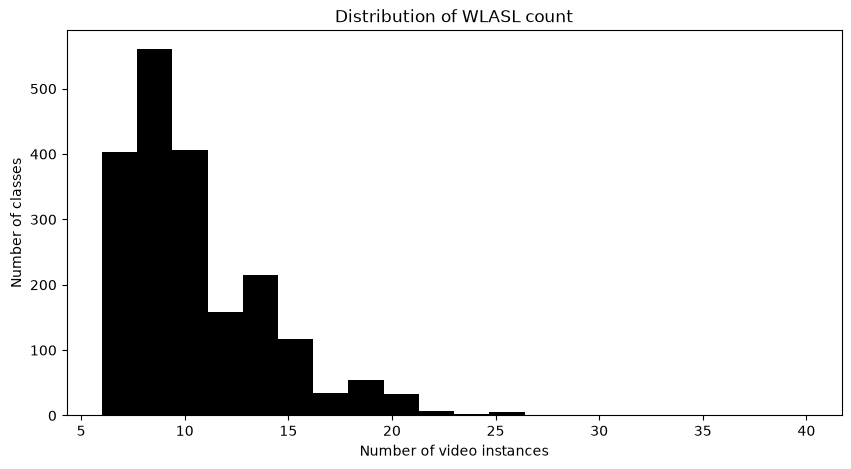

In [65]:
# Histogram: distribution of counts of video instances
# Most WLASL classes have approximately 7-12 instances; relatively few classes have more than 20
plt.figure(figsize=(10, 5))
plt.hist(counts, bins=20, color="black")
plt.xlabel("Number of video instances")
plt.ylabel("Number of classes")
plt.title("Distribution of WLASL count")
plt.show()

In [66]:
# Inspecting the video files

# Loading the video files
VIDEOS_DIR = DATA_DIR / "videos"
video_files = list(VIDEOS_DIR.glob("*.mp4"))

In [68]:
# Number of video files
print(len(video_files))     # Gives 11980 whis is not equal to 21083 (Total video instances from before)

# First 10 video files
print(video_files[:10])

11980
[PosixPath('../data/raw/videos/52291.mp4'), PosixPath('../data/raw/videos/34114.mp4'), PosixPath('../data/raw/videos/60545.mp4'), PosixPath('../data/raw/videos/17915.mp4'), PosixPath('../data/raw/videos/51940.mp4'), PosixPath('../data/raw/videos/39430.mp4'), PosixPath('../data/raw/videos/69207.mp4'), PosixPath('../data/raw/videos/51798.mp4'), PosixPath('../data/raw/videos/38048.mp4'), PosixPath('../data/raw/videos/66652.mp4')]


In [75]:
# Comparing video ids from the metadata with the video ids from video files

local_video_ids = {video.stem for video in video_files}
meta_data_instance_ids = {instance.get("video_id") for item in data for instance in item["instances"]}

print(len(local_video_ids))         # Unique local video ids
print(sum(counts))                  # Total metadata instances
print(len(meta_data_instance_ids))  # Unique metadata video ids

 # Videos found in both metadata and local video files
print(len(meta_data_instance_ids & local_video_ids))

# Video ids only in metadata but not local videos
print(len(meta_data_instance_ids - local_video_ids))

# Conclusion: No duplicate video ids in the metadata as total instances and unique metadata ids
# are same. Also, all 11,980 video ids appear in metadata. 9,103 videos are missing locally.'''

11980
21083
21083
11980
9103
